In [15]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/muhammadharisabid/fabricdefectntu/README.roboflow.txt
/kaggle/input/datasets/muhammadharisabid/fabricdefectntu/data.yaml
/kaggle/input/datasets/muhammadharisabid/fabricdefectntu/valid/labels/IMG-20230803-WA0043_jpg.rf.4a7fc25d63094df1086c937530be065d.txt
/kaggle/input/datasets/muhammadharisabid/fabricdefectntu/valid/labels/IMG-20230817-WA0059_jpg.rf.210346fc4ef7aea8139cff0f27886636.txt
/kaggle/input/datasets/muhammadharisabid/fabricdefectntu/valid/labels/augmented_topbasi-28-_jpg.rf.3854f3fef56e150116c9d5516c7442a2.txt
/kaggle/input/datasets/muhammadharisabid/fabricdefectntu/valid/labels/IMG-20230914-WA0088_jpg.rf.e655a0b26db44ce2b40be13469bc8c5d.txt
/kaggle/input/datasets/muhammadharisabid/fabricdefectntu/valid/labels/IMG-20230907-WA0045_jpg.rf.48a404f5f38ea62ebf3879f73bd18a3e.txt
/kaggle/input/datasets/muhammadharisabid/fabricdefectntu/valid/labels/IMG-20230808-WA0040_jpg.rf.e8e8409906f716856ea50b371f8d20f7.txt
/kaggle/input/datasets/muhammadharisabid/fabricdef

In [ ]:
!pip install -q ultralytics pyyaml

import os
import sys
import time
import shutil
import yaml
import json
import glob
from pathlib import Path

import torch
import pandas as pd

assert torch.cuda.is_available(), (
    "GPU is required. Go to Kaggle -> Settings -> Accelerator -> GPU"
)

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)

from ultralytics import YOLO
from ultralytics.utils.torch_utils import get_flops

print("Ultralytics:", "OK")

GPU: Tesla T4
PyTorch: 2.11.0+cu128
Ultralytics: OK


In [ ]:
from pathlib import Path

CODE_DIR = Path("/kaggle/working/E_EAF_YOLO11n/code")
CODE_DIR.mkdir(parents=True, exist_ok=True)

eaf_code = r'''
import inspect
from pathlib import Path
import torch
import torch.nn as nn
import yaml
import ultralytics.nn.tasks as tasks
import ultralytics.nn.modules as modules


class ECA(nn.Module):
    def __init__(self, c1=None, c2=None, k=3):
        super().__init__()
        kernel = 3

        if isinstance(c1, int) and c1 in (3, 5, 7):
            kernel = c1
        elif isinstance(k, int) and k in (3, 5, 7):
            kernel = k

        self.avg_pool = nn.AdaptiveAvgPool2d(1)

        self.conv = nn.Conv1d(
            1,
            1,
            kernel_size=kernel,
            padding=(kernel - 1) // 2,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        y = self.avg_pool(x)

        y = self.conv(
            y.squeeze(-1).transpose(-1, -2)
        ).transpose(-1, -2).unsqueeze(-1)

        return x * self.sigmoid(y)


class AFF(nn.Module):
    def __init__(self, in_channels, out_channels=None):
        super().__init__()

        if isinstance(in_channels, int) and out_channels is None:
            out_channels = in_channels
            in_channels = [in_channels, in_channels]

        elif isinstance(in_channels, int) and isinstance(out_channels, int):
            in_channels = [in_channels, out_channels]

        self.out_channels = out_channels

        self.conv_adapters = nn.ModuleList([
            nn.Conv2d(c, out_channels, 1, bias=False)
            if c != out_channels else nn.Identity()
            for c in in_channels
        ])

        mid = max(out_channels // 4, 16)

        self.conv1 = nn.Conv2d(
            out_channels,
            mid,
            1,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(mid)
        self.relu = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv2d(
            mid,
            out_channels,
            1,
            bias=False
        )

        self.bn2 = nn.BatchNorm2d(out_channels)

        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, xs):

        if not isinstance(xs, (list, tuple)):
            xs = [xs]

        x0 = self.conv_adapters[0](xs[0])

        x1 = (
            self.conv_adapters[1](xs[1])
            if len(xs) > 1
            else x0
        )

        x_sum = x0 + x1

        loc = self.bn2(
            self.conv2(
                self.relu(
                    self.bn1(
                        self.conv1(x_sum)
                    )
                )
            )
        )

        glo = self.bn2(
            self.conv2(
                self.relu(
                    self.bn1(
                        self.conv1(
                            self.global_pool(x_sum)
                        )
                    )
                )
            )
        )

        weight = self.sigmoid(loc + glo)

        return x0 * weight + x1 * (1.0 - weight)


def register():

    tasks.ECA = ECA
    modules.ECA = ECA

    tasks.AFF = AFF
    modules.AFF = AFF

  
    try:
        src = inspect.getsource(tasks.parse_model)

    except OSError:
        print("inspect.getsource() unavailable.")
        print("Using Ultralytics tasks.py directly...")

        tasks_file = Path(tasks.__file__).resolve()

        if not tasks_file.exists():
            raise FileNotFoundError(
                f"Ultralytics tasks.py not found: {tasks_file}"
            )

        full_source = tasks_file.read_text(
            encoding="utf-8"
        )

        tree = ast.parse(full_source)

        parse_node = None

        for node in tree.body:
            if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
                if node.name == "parse_model":
                    parse_node = node
                    break

        if parse_node is None:
            raise RuntimeError(
                "Could not find parse_model() inside Ultralytics tasks.py"
            )

        src = ast.get_source_segment(
            full_source,
            parse_node
        )

        if not src:
            raise RuntimeError(
                "Could not extract parse_model() source."
            )

        print(
            "Loaded parse_model from:",
            tasks_file
        )


    target = (
        "elif m is Concat:\n"
        "            c2 = sum(ch[x] for x in f)"
    )

    replacement = target + """
        elif m is AFF:
            c2 = args[0] if len(args) else ch[f[-1]]
            args = [[ch[x] for x in f], c2]
"""

   
    if "elif m is AFF:" not in src:

        if target not in src:
            raise RuntimeError(
                "Could not find the expected Concat branch "
                "inside Ultralytics parse_model(). "
                "Ultralytics version may have changed."
            )

        new_src = src.replace(
            target,
            replacement,
            1
        )

    
        globs = tasks.__dict__.copy()

        globs["ECA"] = ECA
        globs["AFF"] = AFF

        exec(
            new_src,
            globs
        )

        tasks.parse_model = globs["parse_model"]

        print(
            "AFF parser patch applied successfully."
        )

    else:
        print(
            "AFF parser patch already present."
        )
register()



ABLATIONS = {
    "A_base":        (False, False, False),
    "B_p2":          (True,  False, False),
    "C_eca":         (False, True,  False),
    "D_p2_eca":      (True,  True,  False),
    "E_EAF_YOLO11n": (True,  True,  True),
}


def write_cfg(cfg_dir, tag, nc=7):

    p2, eca, aff = ABLATIONS[tag]

    cfg_path = Path(cfg_dir) / f"{tag}.yaml"

    fuse_mod = "AFF" if aff else "Concat"

    backbone = [
        [-1, 1, "Conv", [64, 3, 2]],
        [-1, 1, "Conv", [128, 3, 2]],
        [-1, 2, "C3k2", [256, False, 0.25]],
        [-1, 1, "Conv", [256, 3, 2]],
        [-1, 2, "C3k2", [512, False, 0.25]],
        [-1, 1, "Conv", [512, 3, 2]],
        [-1, 2, "C3k2", [512, True]],
        [-1, 1, "Conv", [1024, 3, 2]],
        [-1, 2, "C3k2", [1024, True]],
        [-1, 1, "SPPF", [1024, 5]],
        [-1, 2, "C2PSA", [1024]],
    ]

    if not p2:

        head = [
            [-1, 1, "nn.Upsample", [None, 2, "nearest"]],
            [[-1, 6], 1, fuse_mod, [128] if aff else [1]],
            [-1, 2, "C3k2", [512, False]],

            [-1, 1, "nn.Upsample", [None, 2, "nearest"]],
            [[-1, 4], 1, fuse_mod, [64] if aff else [1]],
            [-1, 2, "C3k2", [256, False]],

            [-1, 1, "Conv", [256, 3, 2]],
            [[-1, 13], 1, fuse_mod, [128] if aff else [1]],
            [-1, 2, "C3k2", [512, False]],

            [-1, 1, "Conv", [512, 3, 2]],
            [[-1, 10], 1, fuse_mod, [256] if aff else [1]],
            [-1, 2, "C3k2", [1024, True]],
        ]

        det_ins = [16, 19, 22]

        if eca:

            head.append([16, 1, "ECA", [3]])
            head.append([19, 1, "ECA", [3]])
            head.append([22, 1, "ECA", [3]])

            det_ins = [23, 24, 25]

        head.append(
            [det_ins, 1, "Detect", [nc]]
        )

    else:

        head = [
            [-1, 1, "nn.Upsample", [None, 2, "nearest"]],
            [[-1, 6], 1, fuse_mod, [128] if aff else [1]],
            [-1, 2, "C3k2", [512, False]],

            [-1, 1, "nn.Upsample", [None, 2, "nearest"]],
            [[-1, 4], 1, fuse_mod, [64] if aff else [1]],
            [-1, 2, "C3k2", [256, False]],

            [-1, 1, "nn.Upsample", [None, 2, "nearest"]],
            [[-1, 2], 1, fuse_mod, [32] if aff else [1]],
            [-1, 2, "C3k2", [128, False]],

            [-1, 1, "Conv", [128, 3, 2]],
            [[-1, 16], 1, fuse_mod, [64] if aff else [1]],
            [-1, 2, "C3k2", [256, False]],

            [-1, 1, "Conv", [256, 3, 2]],
            [[-1, 13], 1, fuse_mod, [128] if aff else [1]],
            [-1, 2, "C3k2", [512, False]],

            [-1, 1, "Conv", [512, 3, 2]],
            [[-1, 10], 1, fuse_mod, [256] if aff else [1]],
            [-1, 2, "C3k2", [1024, True]],
        ]

        det_ins = [19, 22, 25, 28]

        if eca:

            head.append([19, 1, "ECA", [3]])
            head.append([22, 1, "ECA", [3]])
            head.append([25, 1, "ECA", [3]])
            head.append([28, 1, "ECA", [3]])

            det_ins = [29, 30, 31, 32]

        head.append(
            [det_ins, 1, "Detect", [nc]]
        )

    cfg_dict = {
        "nc": nc,
        "scales": {
            "n": [0.50, 0.25, 1024]
        },
        "backbone": backbone,
        "head": head
    }

    with open(cfg_path, "w") as f:
        yaml.safe_dump(cfg_dict, f)

    return cfg_path
'''


module_path = CODE_DIR / "eaf_modules.py"

with open(module_path, "w", encoding="utf-8") as f:
    f.write(eaf_code)

print("EAF module recreated successfully.")
print("Path:", module_path)
print("Size:", module_path.stat().st_size, "bytes")

EAF module recreated successfully.
Path: /kaggle/working/E_EAF_YOLO11n/code/eaf_modules.py
Size: 9703 bytes


In [ ]:

module_candidates = list(WORK_ROOT.rglob("eaf_modules.py"))

if not module_candidates:
    raise FileNotFoundError(
        f"eaf_modules.py was not found in {WORK_ROOT}"
    )

EAF_SOURCE = module_candidates[0]

print("EAF module found:")
print(EAF_SOURCE)

EAF module found:
/kaggle/working/E_EAF_YOLO11n/code/eaf_modules.py


In [ ]:


TAG = "E_EAF_YOLO11n"
SEED = 42

EPOCHS = 200

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working") / TAG

RUNS_DIR = WORK_ROOT / "runs"
CFG_DIR = WORK_ROOT / "configs"
CODE_DIR = WORK_ROOT / "code"
RES_DIR = WORK_ROOT / "results"

for p in (RUNS_DIR, CFG_DIR, CODE_DIR, RES_DIR):
    p.mkdir(parents=True, exist_ok=True)

print("Searching Kaggle input...")
print(INPUT_ROOT)



module_candidates = list(WORK_ROOT.rglob("eaf_modules.py"))

if not module_candidates:
    raise FileNotFoundError(
        """
eaf_modules.py was not found.

Attach the Kaggle Dataset containing eaf_modules.py
to this notebook.
"""
    )

EAF_SOURCE = module_candidates[0]



print("EAF module found:")
print(EAF_SOURCE)


yaml_candidates = list(INPUT_ROOT.rglob("data.yaml"))


DATA_SOURCE = None

for candidate in yaml_candidates:

    parent = candidate.parent

    has_train = (parent / "train").is_dir()

    has_valid = (
        (parent / "valid").is_dir()
        or
        (parent / "val").is_dir()
    )

    has_test = (parent / "test").is_dir()

    if has_train and has_valid and has_test:
        DATA_SOURCE = candidate
        break

if DATA_SOURCE is None:
    raise FileNotFoundError(
        """
Could not find data.yaml with:

train/
valid/ or val/
test/
"""
    )

print("\nDataset YAML:")
print(DATA_SOURCE)

Searching Kaggle input...
/kaggle/input
EAF module found:
/kaggle/working/E_EAF_YOLO11n/code/eaf_modules.py

Dataset YAML:
/kaggle/input/datasets/muhammadharisabid/fabricdefectntu/data.yaml


In [ ]:


from pathlib import Path

CODE_DIR = Path("/kaggle/working/E_EAF_YOLO11n/code")
CODE_DIR.mkdir(parents=True, exist_ok=True)

eaf_code = r'''
import ast
import inspect
from pathlib import Path

import torch
import torch.nn as nn
import yaml

import ultralytics.nn.tasks as tasks
import ultralytics.nn.modules as modules



class ECA(nn.Module):

    def __init__(self, c1=None, c2=None, k=3):

        super().__init__()

        kernel = 3

        if isinstance(c1, int) and c1 in (3, 5, 7):
            kernel = c1

        elif isinstance(k, int) and k in (3, 5, 7):
            kernel = k

        self.avg_pool = nn.AdaptiveAvgPool2d(1)

        self.conv = nn.Conv1d(
            1,
            1,
            kernel_size=kernel,
            padding=(kernel - 1) // 2,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()


    def forward(self, x):

        y = self.avg_pool(x)

        y = self.conv(
            y.squeeze(-1).transpose(-1, -2)
        ).transpose(-1, -2).unsqueeze(-1)

        return x * self.sigmoid(y)


class AFF(nn.Module):

    def __init__(self, in_channels, out_channels=None):

        super().__init__()

        if isinstance(in_channels, int) and out_channels is None:

            out_channels = in_channels
            in_channels = [in_channels, in_channels]

        elif (
            isinstance(in_channels, int)
            and isinstance(out_channels, int)
        ):

            in_channels = [in_channels, out_channels]

        self.out_channels = out_channels

        self.conv_adapters = nn.ModuleList([

            nn.Conv2d(
                c,
                out_channels,
                1,
                bias=False
            )
            if c != out_channels
            else nn.Identity()

            for c in in_channels

        ])

        mid = max(out_channels // 4, 16)

        self.conv1 = nn.Conv2d(
            out_channels,
            mid,
            1,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(mid)

        self.relu = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv2d(
            mid,
            out_channels,
            1,
            bias=False
        )

        self.bn2 = nn.BatchNorm2d(out_channels)

        self.global_pool = nn.AdaptiveAvgPool2d(1)

        self.sigmoid = nn.Sigmoid()


    def forward(self, xs):

        if not isinstance(xs, (list, tuple)):
            xs = [xs]

        x0 = self.conv_adapters[0](xs[0])

        x1 = (
            self.conv_adapters[1](xs[1])
            if len(xs) > 1
            else x0
        )

        x_sum = x0 + x1

        loc = self.bn2(
            self.conv2(
                self.relu(
                    self.bn1(
                        self.conv1(x_sum)
                    )
                )
            )
        )

        glo = self.bn2(
            self.conv2(
                self.relu(
                    self.bn1(
                        self.conv1(
                            self.global_pool(x_sum)
                        )
                    )
                )
            )
        )

        weight = self.sigmoid(loc + glo)

        return (
            x0 * weight
            + x1 * (1.0 - weight)
        )



def register():



    tasks.ECA = ECA
    modules.ECA = ECA

    tasks.AFF = AFF
    modules.AFF = AFF


    try:

        src = inspect.getsource(
            tasks.parse_model
        )

        print(
            "parse_model source obtained with inspect."
        )

    except OSError:

        print(
            "inspect.getsource() unavailable."
        )

        print(
            "Reading Ultralytics tasks.py directly..."
        )

        tasks_file = Path(
            tasks.__file__
        ).resolve()

        print(
            "Ultralytics tasks.py:",
            tasks_file
        )

        if not tasks_file.exists():

            raise FileNotFoundError(
                f"Could not find tasks.py: {tasks_file}"
            )

        full_source = tasks_file.read_text(
            encoding="utf-8"
        )

        tree = ast.parse(
            full_source
        )

        parse_node = None

        for node in tree.body:

            if isinstance(
                node,
                (ast.FunctionDef, ast.AsyncFunctionDef)
            ):

                if node.name == "parse_model":

                    parse_node = node
                    break

        if parse_node is None:

            raise RuntimeError(
                "Could not find parse_model() in tasks.py"
            )

        src = ast.get_source_segment(
            full_source,
            parse_node
        )

        if not src:

            raise RuntimeError(
                "Could not extract parse_model() source."
            )

        print(
            "parse_model source extracted successfully."
        )


    target = (
        "elif m is Concat:\n"
        "            c2 = sum(ch[x] for x in f)"
    )

    replacement = target + """
        elif m is AFF:
            c2 = args[0] if len(args) else ch[f[-1]]
            args = [[ch[x] for x in f], c2]
"""

    if "elif m is AFF:" not in src:

        if target not in src:

            raise RuntimeError(
                "Expected Concat branch was not found "
                "inside Ultralytics parse_model()."
            )

        new_src = src.replace(
            target,
            replacement,
            1
        )

        globs = tasks.__dict__.copy()

        globs["ECA"] = ECA
        globs["AFF"] = AFF

        exec(
            new_src,
            globs
        )

        tasks.parse_model = globs[
            "parse_model"
        ]

        print(
            "AFF parser patch applied successfully."
        )

    else:

        print(
            "AFF parser patch already present."
        )

ABLATIONS = {

    "A_base":
        (False, False, False),

    "B_p2":
        (True, False, False),

    "C_eca":
        (False, True, False),

    "D_p2_eca":
        (True, True, False),

    "E_EAF_YOLO11n":
        (True, True, True),

}



def write_cfg(
    cfg_dir,
    tag,
    nc=7
):

    p2, eca, aff = ABLATIONS[tag]

    cfg_path = (
        Path(cfg_dir)
        / f"{tag}.yaml"
    )

    fuse_mod = (
        "AFF"
        if aff
        else "Concat"
    )

    backbone = [

        [-1, 1, "Conv", [64, 3, 2]],

        [-1, 1, "Conv", [128, 3, 2]],

        [-1, 2, "C3k2",
         [256, False, 0.25]],

        [-1, 1, "Conv",
         [256, 3, 2]],

        [-1, 2, "C3k2",
         [512, False, 0.25]],

        [-1, 1, "Conv",
         [512, 3, 2]],

        [-1, 2, "C3k2",
         [512, True]],

        [-1, 1, "Conv",
         [1024, 3, 2]],

        [-1, 2, "C3k2",
         [1024, True]],

        [-1, 1, "SPPF",
         [1024, 5]],

        [-1, 2, "C2PSA",
         [1024]],

    ]


    if not p2:

        head = [

            [-1, 1, "nn.Upsample",
             [None, 2, "nearest"]],

            [[-1, 6], 1,
             fuse_mod,
             [128] if aff else [1]],

            [-1, 2, "C3k2",
             [512, False]],

            [-1, 1, "nn.Upsample",
             [None, 2, "nearest"]],

            [[-1, 4], 1,
             fuse_mod,
             [64] if aff else [1]],

            [-1, 2, "C3k2",
             [256, False]],

            [-1, 1, "Conv",
             [256, 3, 2]],

            [[-1, 13], 1,
             fuse_mod,
             [128] if aff else [1]],

            [-1, 2, "C3k2",
             [512, False]],

            [-1, 1, "Conv",
             [512, 3, 2]],

            [[-1, 10], 1,
             fuse_mod,
             [256] if aff else [1]],

            [-1, 2, "C3k2",
             [1024, True]],

        ]

        det_ins = [16, 19, 22]

        if eca:

            head.append(
                [16, 1, "ECA", [3]]
            )

            head.append(
                [19, 1, "ECA", [3]]
            )

            head.append(
                [22, 1, "ECA", [3]]
            )

            det_ins = [23, 24, 25]

        head.append(
            [det_ins, 1, "Detect", [nc]]
        )

    else:

        head = [

            [-1, 1, "nn.Upsample",
             [None, 2, "nearest"]],

            [[-1, 6], 1,
             fuse_mod,
             [128] if aff else [1]],

            [-1, 2, "C3k2",
             [512, False]],

            [-1, 1, "nn.Upsample",
             [None, 2, "nearest"]],

            [[-1, 4], 1,
             fuse_mod,
             [64] if aff else [1]],

            [-1, 2, "C3k2",
             [256, False]],

            [-1, 1, "nn.Upsample",
             [None, 2, "nearest"]],

            [[-1, 2], 1,
             fuse_mod,
             [32] if aff else [1]],

            [-1, 2, "C3k2",
             [128, False]],

            [-1, 1, "Conv",
             [128, 3, 2]],

            [[-1, 16], 1,
             fuse_mod,
             [64] if aff else [1]],

            [-1, 2, "C3k2",
             [256, False]],

            [-1, 1, "Conv",
             [256, 3, 2]],

            [[-1, 13], 1,
             fuse_mod,
             [128] if aff else [1]],

            [-1, 2, "C3k2",
             [512, False]],

            [-1, 1, "Conv",
             [512, 3, 2]],

            [[-1, 10], 1,
             fuse_mod,
             [256] if aff else [1]],

            [-1, 2, "C3k2",
             [1024, True]],

        ]

        det_ins = [
            19, 22, 25, 28
        ]

        if eca:

            head.append(
                [19, 1, "ECA", [3]]
            )

            head.append(
                [22, 1, "ECA", [3]]
            )

            head.append(
                [25, 1, "ECA", [3]]
            )

            head.append(
                [28, 1, "ECA", [3]]
            )

            det_ins = [
                29, 30, 31, 32
            ]

        head.append(
            [det_ins, 1, "Detect", [nc]]
        )


    cfg_dict = {

        "nc": nc,

        "scales": {
            "n": [0.50, 0.25, 1024]
        },

        "backbone": backbone,

        "head": head

    }


    with open(
        cfg_path,
        "w"
    ) as f:

        yaml.safe_dump(
            cfg_dict,
            f
        )

    return cfg_path
'''

module_path = CODE_DIR / "eaf_modules.py"

with open(
    module_path,
    "w",
    encoding="utf-8"
) as f:
    f.write(eaf_code)

print("EAF module recreated successfully.")
print("Path:", module_path)
print("Size:", module_path.stat().st_size, "bytes")

EAF module recreated successfully.
Path: /kaggle/working/E_EAF_YOLO11n/code/eaf_modules.py
Size: 11484 bytes


In [ ]:


import sys
import importlib

if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

if "eaf_modules" in sys.modules:
    del sys.modules["eaf_modules"]

import eaf_modules as eaf

print("Loaded:")
print(eaf.__file__)

Loaded:
/kaggle/working/E_EAF_YOLO11n/code/eaf_modules.py


In [ ]:
from pathlib import Path
import yaml

# Dataset location
DATASET_DIR = Path(
    "/kaggle/input/datasets/muhammadharisabid/fabricdefectntu"
)

# Original YAML
DATA_SOURCE = DATASET_DIR / "data.yaml"

# Read original YAML
with open(DATA_SOURCE, "r", encoding="utf-8") as f:
    src = yaml.safe_load(f)

# Classes
names = src["names"]
NC = len(names)

# Actual folder structure confirmed from inspection
train_name = "train"
val_name = "valid"
test_name = "test"

# Create writable YAML in /kaggle/working
DATA_YAML = Path(
    "/kaggle/working/data_kaggle.yaml"
)

yaml.safe_dump(
    {
        "path": str(DATASET_DIR),

        "train": "train/images",

        "val": "valid/images",

        "test": "test/images",

        "nc": NC,

        "names": names,
    },

    open(
        DATA_YAML,
        "w",
        encoding="utf-8"
    ),

    sort_keys=False
)

print("================================")
print("DATA YAML CREATED")
print("================================")

print("Classes :", NC)
print("Names   :", names)

print("\nTrain :", train_name)
print("Val   :", val_name)
print("Test  :", test_name)

print("\nDATASET_DIR:")
print(DATASET_DIR)

print("\nDATA_YAML:")
print(DATA_YAML)

DATA YAML CREATED
Classes : 7
Names   : ['baekra', 'color issues', 'contamination', 'cut', 'gray stitch', 'selvet', 'stain']

Train : train
Val   : valid
Test  : test

DATASET_DIR:
/kaggle/input/datasets/muhammadharisabid/fabricdefectntu

DATA_YAML:
/kaggle/working/data_kaggle.yaml


In [ ]:
from pathlib import Path
import yaml


DATASET_DIR = Path(
    "/kaggle/input/datasets/muhammadharisabid/fabricdefectntu"
)

DATA_SOURCE = DATASET_DIR / "data.yaml"


with open(
    DATA_SOURCE,
    "r",
    encoding="utf-8"
) as f:

    src = yaml.safe_load(f)

train_path = src["train"]
val_path = src["val"]
test_path = src.get("test")

NC = len(src["names"])


def resolve_dataset_path(path):

    path = Path(path)

    if path.is_absolute():
        return path

    return DATASET_DIR / path


train_images_dir = resolve_dataset_path(train_path)
val_images_dir = resolve_dataset_path(val_path)

if test_path:
    test_images_dir = resolve_dataset_path(test_path)
else:
    test_images_dir = None


IMAGE_EXTS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}


def count_images(folder):

    if not folder.exists():
        return 0

    return sum(
        1
        for p in folder.rglob("*")
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTS
    )


def get_labels_dir(images_dir):

    return images_dir.parent / "labels"



def count_labels(images_dir):

    label_dir = get_labels_dir(images_dir)

    if not label_dir.exists():
        return 0

    return len(
        list(label_dir.glob("*.txt"))
    )


train_images = count_images(train_images_dir)
val_images = count_images(val_images_dir)

train_labels = count_labels(train_images_dir)
val_labels = count_labels(val_images_dir)


if test_images_dir is not None:

    test_images = count_images(test_images_dir)
    test_labels = count_labels(test_images_dir)

else:

    test_images = 0
    test_labels = 0


print("================================")
print("DATASET PATHS")
print("================================")

print("Train images :", train_images_dir)
print("Val images   :", val_images_dir)
print("Test images  :", test_images_dir)


print("\n================================")
print("DATASET SUMMARY")
print("================================")

print("Train images :", train_images)
print("Train labels :", train_labels)

print("Val images   :", val_images)
print("Val labels   :", val_labels)

print("Test images  :", test_images)
print("Test labels  :", test_labels)

print("Classes      :", NC)

print("================================")

DATASET PATHS
Train images : /kaggle/input/datasets/muhammadharisabid/fabricdefectntu/../train/images
Val images   : /kaggle/input/datasets/muhammadharisabid/fabricdefectntu/../valid/images
Test images  : /kaggle/input/datasets/muhammadharisabid/fabricdefectntu/../test/images

DATASET SUMMARY
Train images : 0
Train labels : 0
Val images   : 0
Val labels   : 0
Test images  : 0
Test labels  : 0
Classes      : 7


In [29]:
from pathlib import Path

CODE_DIR = Path("/kaggle/working/E_EAF_YOLO11n/code")

print("CODE_DIR:", CODE_DIR)
print("\nFiles inside code folder:")

for p in CODE_DIR.iterdir():
    print(" -", p.name)

EAF_FILE = CODE_DIR / "eaf_modules.py"

print("\nEAF module exists:", EAF_FILE.exists())

if EAF_FILE.exists():
    print("EAF module:", EAF_FILE)
    print("Size:", EAF_FILE.stat().st_size, "bytes")

CODE_DIR: /kaggle/working/E_EAF_YOLO11n/code

Files inside code folder:
 - __pycache__
 - eaf_modules.py

EAF module exists: True
EAF module: /kaggle/working/E_EAF_YOLO11n/code/eaf_modules.py
Size: 11484 bytes


In [ ]:

import ultralytics
import inspect
import ultralytics.nn.tasks as tasks

print("Ultralytics version:", ultralytics.__version__)
print("parse_model:", tasks.parse_model)

try:
    print("parse_model file:", inspect.getfile(tasks.parse_model))
except Exception as e:
    print("Could not get file:", repr(e))

print("parse_model filename:", tasks.parse_model.__code__.co_filename)

try:
    src = inspect.getsource(tasks.parse_model)
    print("\nSource available: YES")
    print("Source length:", len(src))
except Exception as e:
    print("\nSource available: NO")
    print("Error:", repr(e))

Ultralytics version: 8.4.174
parse_model: <function parse_model at 0x7a19bb3f84a0>
parse_model file: /usr/local/lib/python3.13/dist-packages/ultralytics/nn/tasks.py
parse_model filename: /usr/local/lib/python3.13/dist-packages/ultralytics/nn/tasks.py

Source available: YES
Source length: 8263


In [ ]:
sys.path.insert(
    0,
    str(CODE_DIR)
)

import eaf_modules as eaf

# IMPORTANT:
# Must be executed in every fresh Kaggle session.
eaf.register()

print("EAF module registered successfully.")

CFG = eaf.write_cfg(
    CFG_DIR,
    TAG,
    NC
)

print("EAF configuration:")
print(CFG)

parse_model source obtained with inspect.
AFF parser patch applied successfully.
EAF module registered successfully.
EAF configuration:
/kaggle/working/E_EAF_YOLO11n/configs/E_EAF_YOLO11n.yaml


In [ ]:

model_test = YOLO(
    str(CFG)
).model

model_test.train()

x = torch.randn(
    2,
    3,
    320,
    320
)

out = model_test(x)


def tensors(obj):

    if torch.is_tensor(obj):

        yield obj

    elif isinstance(obj, dict):

        for value in obj.values():
            yield from tensors(value)

    elif isinstance(obj, (list, tuple)):

        for value in obj:
            yield from tensors(value)


loss_proxy = sum(
    t.float().pow(2).mean()
    for t in tensors(out)
)

loss_proxy.backward()


dead = [
    name
    for name, parameter
    in model_test.named_parameters()
    if parameter.requires_grad
    and parameter.grad is None
]


assert not dead, (
    f"Parameters without gradients: {dead[:10]}"
)


params_m = (
    sum(
        p.numel()
        for p in model_test.parameters()
    )
    / 1e6
)


print("================================")
print("EAF SANITY CHECK: PASS")
print("================================")
print(
    "Parameters:",
    round(params_m, 3),
    "M"
)
print("================================")


del model_test
del out
del x

torch.cuda.empty_cache()

WARNING ⚠️ no model scale passed. Assuming scale='n'.
EAF SANITY CHECK: PASS
Parameters: 2.729 M


In [ ]:

TRAIN_CFG = dict(

    data=str(DATA_YAML),

    imgsz=640,

    epochs=EPOCHS,

    batch=16,

    device=0,

    workers=2,


    optimizer="AdamW",

    # Lower LR = more stable fine tuning
    lr0=5e-4,

    lrf=0.01,

    weight_decay=5e-4,

    cos_lr=True,

    warmup_epochs=3.0,


    hsv_h=0.01,

    hsv_s=0.35,

    hsv_v=0.25,


    degrees=2.0,

    translate=0.05,

    scale=0.20,

    shear=1.0,

    perspective=0.0,


    fliplr=0.5,

    # Important for fabric:
    # don't vertically flip the fabric defects
    flipud=0.0,


    mosaic=0.70,

    close_mosaic=20,

    # Don't combine unrelated defect images
    mixup=0.0,


    label_smoothing=0.02,


    amp=True,

    cache=False,

    seed=SEED,

    deterministic=True,


    project=str(RUNS_DIR),

    name=TAG,

    exist_ok=True,

    plots=True,

    save=True,

   
    save_period=10,

    patience=30,
)


print("Training configuration:\n")

for key, value in TRAIN_CFG.items():

    print(
        f"{key:20} : {value}"
    )

Training configuration:

data                 : /kaggle/working/data_kaggle.yaml
imgsz                : 640
epochs               : 200
batch                : 16
device               : 0
workers              : 2
optimizer            : AdamW
lr0                  : 0.0005
lrf                  : 0.01
weight_decay         : 0.0005
cos_lr               : True
warmup_epochs        : 3.0
hsv_h                : 0.01
hsv_s                : 0.35
hsv_v                : 0.25
degrees              : 2.0
translate            : 0.05
scale                : 0.2
shear                : 1.0
perspective          : 0.0
fliplr               : 0.5
flipud               : 0.0
mosaic               : 0.7
close_mosaic         : 20
mixup                : 0.0
label_smoothing      : 0.02
amp                  : True
cache                : False
seed                 : 42
deterministic        : True
project              : /kaggle/working/E_EAF_YOLO11n/runs
name                 : E_EAF_YOLO11n
exist_ok             : True
p

In [ ]:

BEST = (
    RUNS_DIR
    / TAG
    / "weights"
    / "best.pt"
)

LAST = (
    RUNS_DIR
    / TAG
    / "weights"
    / "last.pt"
)

DONE = (
    RUNS_DIR
    / TAG
    / "DONE"
)


if DONE.exists():

    print("================================")
    print("TRAINING ALREADY COMPLETED")
    print("================================")

    print("Best:")
    print(BEST)


elif LAST.exists():

    print("================================")
    print("RESUMING TRAINING")
    print("================================")

    print("Checkpoint:")
    print(LAST)

    model = YOLO(
        str(LAST)
    )

    model.train(
        resume=True
    )

    DONE.touch()

    print("Training resumed successfully.")


else:

    print("================================")
    print("STARTING NEW TRAINING")
    print("================================")

    model = YOLO(
        str(CFG)
    )

    # Transfer pretrained YOLO11n weights
    model.load(
        "yolo11n.pt"
    )

    print("Pretrained YOLO11n weights loaded.")

    model.train(
        **TRAIN_CFG
    )

    DONE.touch()

    print("Training completed.")



print("\nCHECKPOINTS:")

for p in sorted(
    (
        RUNS_DIR
        / TAG
        / "weights"
    ).glob("*.pt")
):

    print(
        p.name,
        "->",
        round(
            p.stat().st_size / 2**20,
            2
        ),
        "MB"
    )

STARTING NEW TRAINING
WARNING ⚠️ no model scale passed. Assuming scale='n'.
Transferred 295/677 items from pretrained weights
Pretrained YOLO11n weights loaded.
WARNING ⚠️ 'label_smoothing' is deprecated and will be removed in the future.
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=20, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/data_kaggle.yaml, degrees=2.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.35, hsv_v=0.25, im

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/200      4.99G      2.911      4.241      3.233         45        640: 100% ━━━━━━━━━━━━ 122/122 5.0it/s 24.3s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 4.4it/s 4.1s0.2s
                   all        562        786      0.494     0.0665     0.0463     0.0137

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/200         5G      2.652      3.897      3.045         33        640: 100% ━━━━━━━━━━━━ 122/122 5.0it/s 24.4s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 4.0it/s 4.5s0.2s
                   all        562        786      0.245      0.135     0.0668     0.0199

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/200         5G      2.484      3.639      2.896         35        640: 100% ━━━━━━━━━━━━ 122/122 4.9it/s 25.0s0.2s
                 Class     Images

In [ ]:


if not BEST.exists():

    raise FileNotFoundError(
        f"best.pt not found at:\n{BEST}"
    )


print("================================")
print("BEST MODEL FOUND")
print("================================")
print(BEST)

print(
    "Size:",
    round(
        BEST.stat().st_size / 2**20,
        2
    ),
    "MB"
)

BEST MODEL FOUND
/kaggle/working/E_EAF_YOLO11n/runs/E_EAF_YOLO11n/weights/best.pt
Size: 5.64 MB


In [ ]:

def evaluate(split):

    mdl = YOLO(
        str(BEST)
    )

    result = mdl.val(

        data=str(DATA_YAML),

        split=split,

        imgsz=640,

        batch=16,

        # Required for standard mAP evaluation
        conf=0.001,

        iou=0.7,

        device=0,

        plots=(split == "test"),

        project=str(
            RES_DIR / "evaluation"
        ),

        name=f"{TAG}_{split}",

        exist_ok=True,

        verbose=False,
    )

    b = result.box

    row = {

        "Model": TAG,

        "Split": split,

        "Precision": float(
            b.mp
        ),

        "Recall": float(
            b.mr
        ),

        "mAP50": float(
            b.map50
        ),

        "mAP75": float(
            b.map75
        ),

        "mAP50-95": float(
            b.map
        ),
    }


    indices = list(
        b.ap_class_index
    )


    pc = pd.DataFrame({

        "class": [
            mdl.names[int(i)]
            for i in indices
        ],

        "Precision": b.p,

        "Recall": b.r,

        "F1": b.f1,

        "AP50": b.ap50,

        "AP50-95": b.ap,

    }).round(4)


    return row, pc


print("Evaluating validation set...")

val_row, val_pc = evaluate(
    "val"
)


print("Evaluating test set...")

test_row, test_pc = evaluate(
    "test"
)


print("\n================================")
print("VALIDATION")
print("================================")

display(
    pd.DataFrame([val_row]).round(4)
)


print("\n================================")
print("TEST")
print("================================")

display(
    pd.DataFrame([test_row]).round(4)
)


print("\n================================")
print("PER-CLASS TEST METRICS")
print("================================")

display(
    test_pc
)

Evaluating validation set...
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
E_EAF_YOLO11n summary (fused): 180 layers, 2,720,760 parameters, 0 gradients, 10.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 107.3±52.6 MB/s, size: 64.3 KB)
val: Scanning /kaggle/input/datasets/muhammadharisabid/fabricdefectntu/valid/labels... 562 images, 38 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 562/562 808.9it/s 0.7s0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/muhammadharisabid/fabricdefectntu/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 6.4it/s 5.6s0.1s
                   all        562        786      0.815      0.814      0.844      0.524
Speed: 0.7ms preprocess, 5.5ms inference, 0.0ms loss, 0.8ms postprocess per image
Evaluating test set...
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
E_EAF_

,Model,Split,Precision,Recall,mAP50,mAP75,mAP50-95
0,E_EAF_YOLO11n,val,0.8153,0.8136,0.8442,0.5787,0.5238



TEST


,Model,Split,Precision,Recall,mAP50,mAP75,mAP50-95
0,E_EAF_YOLO11n,test,0.8403,0.8389,0.8283,0.549,0.526



PER-CLASS TEST METRICS


,class,Precision,Recall,F1,AP50,AP50-95
0,baekra,0.9200,0.9581,0.9386,0.9650,0.7101
1,color issues,0.8025,0.7742,0.7881,0.7416,0.4367
2,contamination,0.9121,1.0000,0.9541,0.9856,0.5608
3,cut,0.6647,0.7021,0.6829,0.5946,0.3817
4,gray stitch,0.8244,0.7083,0.7620,0.6977,0.4531
5,selvet,0.8783,0.8276,0.8522,0.9059,0.5884
6,stain,0.8799,0.9020,0.8908,0.9077,0.5510


In [ ]:


fresh = YOLO(
    str(BEST)
).model.float().cpu().eval()


params_m = (
    sum(
        p.numel()
        for p in fresh.parameters()
    )
    / 1e6
)


try:

    gflops = get_flops(
        fresh,
        640
    )

except Exception:

    gflops = float("nan")


size_mb = (
    BEST.stat().st_size
    / 2**20
)


del fresh


for row in (
    val_row,
    test_row
):

    row.update({

        "Params(M)": params_m,

        "GFLOPs": gflops,

        "Size(MB)": size_mb,

    })


summary = pd.DataFrame([
    val_row,
    test_row
]).round(4)


print("================================")
print("MODEL SUMMARY")
print("================================")

display(summary)


summary.to_csv(
    RES_DIR
    / f"{TAG}_summary.csv",
    index=False
)


test_pc.to_csv(
    RES_DIR
    / f"{TAG}_per_class_test.csv",
    index=False
)


print(
    "Results saved to:",
    RES_DIR
)

MODEL SUMMARY


,Model,Split,Precision,Recall,mAP50,mAP75,mAP50-95,Params(M),GFLOPs,Size(MB)
0,E_EAF_YOLO11n,val,0.8153,0.8136,0.8442,0.5787,0.5238,2.7287,10.7831,5.6453
1,E_EAF_YOLO11n,test,0.8403,0.8389,0.8283,0.5490,0.5260,2.7287,10.7831,5.6453


Results saved to: /kaggle/working/E_EAF_YOLO11n/results


In [ ]:


model = YOLO(
    str(BEST)
)


thresholds = [

    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50,
    0.55,
    0.60,

]


threshold_rows = []


for conf in thresholds:

    print(
        f"Testing confidence = {conf}"
    )

    r = model.val(

        data=str(DATA_YAML),

        split="val",

        imgsz=640,

        batch=16,

        conf=conf,

        iou=0.7,

        device=0,

        plots=False,

        verbose=False,

    )


    precision = float(
        r.box.mp
    )

    recall = float(
        r.box.mr
    )


    if precision + recall > 0:

        f1 = (
            2
            * precision
            * recall
            /
            (precision + recall)
        )

    else:

        f1 = 0.0


    threshold_rows.append({

        "Confidence": conf,

        "Precision": precision,

        "Recall": recall,

        "F1": f1,

    })


threshold_df = pd.DataFrame(
    threshold_rows
)


print("\n================================")
print("CONFIDENCE RESULTS")
print("================================")

display(
    threshold_df.round(4)
)


# ------------------------------------------------------------
# Best F1
# ------------------------------------------------------------

best_f1_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]


# ------------------------------------------------------------
# Highest precision
# ------------------------------------------------------------

best_precision_row = threshold_df.loc[
    threshold_df["Precision"].idxmax()
]


print("\n================================")
print("BEST F1 THRESHOLD")
print("================================")

display(
    pd.DataFrame(
        [best_f1_row]
    ).round(4)
)


print("\n================================")
print("HIGHEST PRECISION THRESHOLD")
print("================================")

display(
    pd.DataFrame(
        [best_precision_row]
    ).round(4)
)


BEST_CONF = float(
    best_f1_row["Confidence"]
)


threshold_df.to_csv(
    RES_DIR
    / f"{TAG}_confidence_sweep.csv",
    index=False
)


print(
    "\nRecommended confidence based on validation F1:",
    BEST_CONF
)

Testing confidence = 0.1
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
E_EAF_YOLO11n summary (fused): 180 layers, 2,720,760 parameters, 0 gradients, 10.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 624.3±1060.4 MB/s, size: 762.2 KB)
val: Scanning /kaggle/input/datasets/muhammadharisabid/fabricdefectntu/valid/labels... 562 images, 38 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 562/562 682.3it/s 0.8s0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/muhammadharisabid/fabricdefectntu/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 6.4it/s 5.6s0.1s
                   all        562        786      0.815      0.814       0.81      0.502
Speed: 0.7ms preprocess, 5.5ms inference, 0.0ms loss, 0.9ms postprocess per image
Testing confidence = 0.15
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
E_EA

,Confidence,Precision,Recall,F1
0,0.10,0.8153,0.8136,0.8144
1,0.15,0.8153,0.8136,0.8144
2,0.20,0.8153,0.8136,0.8144
3,0.25,0.8154,0.8136,0.8145
4,0.30,0.8162,0.8150,0.8156
5,0.35,0.8229,0.8103,0.8165
6,0.40,0.8430,0.7848,0.8129
7,0.45,0.8544,0.7766,0.8137
8,0.50,0.8591,0.7540,0.8032
9,0.55,0.8693,0.7404,0.7997



BEST F1 THRESHOLD


,Confidence,Precision,Recall,F1
5,0.35,0.8229,0.8103,0.8165



HIGHEST PRECISION THRESHOLD


,Confidence,Precision,Recall,F1
10,0.6,0.8823,0.7143,0.7895



Recommended confidence based on validation F1: 0.35


In [ ]:


FINAL_DIR = (
    WORK_ROOT
    / "final_model"
)

FINAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


FINAL_BEST = (
    FINAL_DIR
    / "best.pt"
)

FINAL_LAST = (
    FINAL_DIR
    / "last.pt"
)


shutil.copy2(
    BEST,
    FINAL_BEST
)


if LAST.exists():

    shutil.copy2(
        LAST,
        FINAL_LAST
    )



metadata = {

    "model": TAG,

    "best_model": str(
        FINAL_BEST
    ),

    "confidence_for_deployment": BEST_CONF,

    "imgsz": 640,

    "epochs": EPOCHS,

    "seed": SEED,

    "classes": names,

    "validation_metrics": val_row,

    "test_metrics": test_row,

}


with open(
    FINAL_DIR / "model_info.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2
    )


print("================================")
print("FINAL MODEL")
print("================================")

print(
    "best.pt:",
    FINAL_BEST
)

print(
    "last.pt:",
    FINAL_LAST
)

print(
    "Recommended confidence:",
    BEST_CONF
)

FINAL MODEL
best.pt: /kaggle/working/E_EAF_YOLO11n/final_model/best.pt
last.pt: /kaggle/working/E_EAF_YOLO11n/final_model/last.pt
Recommended confidence: 0.35


Input image:
/kaggle/input/datasets/muhammadharisabid/fabricdefectntu/test/images/WhatsApp-Image-2022-11-18-at-12-59-59-AM_jpeg_jpg.rf.741d289788045b6244d10fe89146fd3d.jpg
Results saved to /kaggle/working/E_EAF_YOLO11n/results/prediction/display


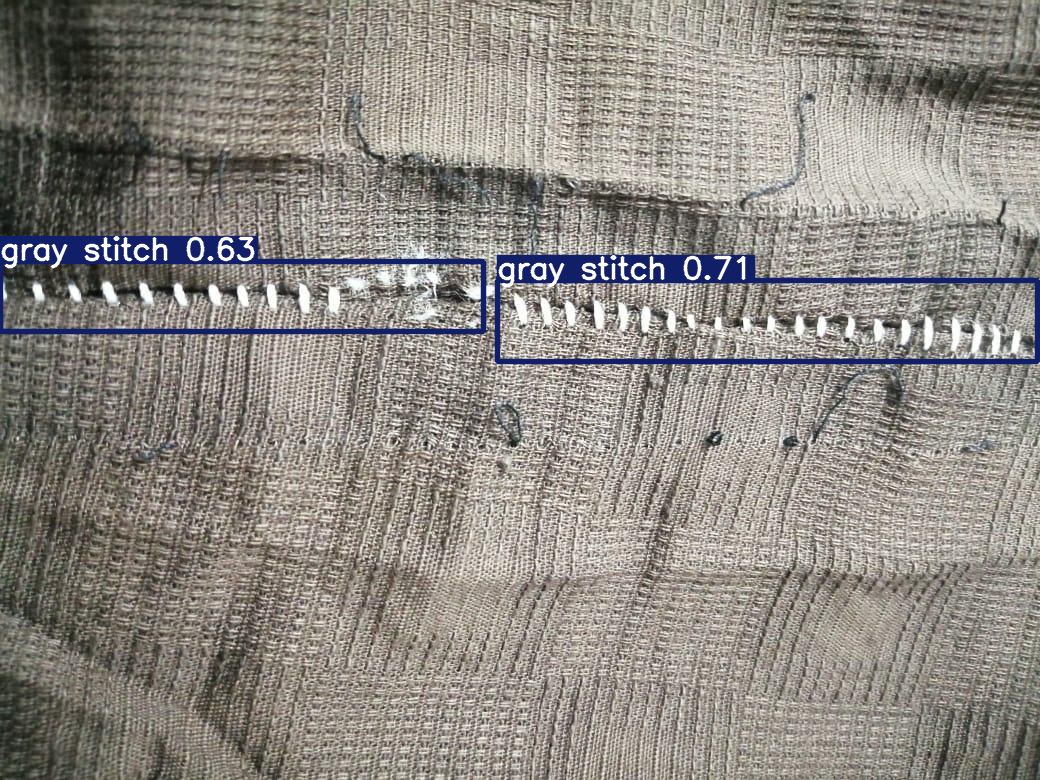


Prediction completed.
Confidence threshold: 0.35


In [ ]:


from ultralytics import YOLO
from pathlib import Path
from IPython.display import display
from PIL import Image

BEST = Path(
    "/kaggle/working/E_EAF_YOLO11n/runs/"
    "E_EAF_YOLO11n/weights/best.pt"
)

model = YOLO(str(BEST))


test_image_dir = (
    DATASET_DIR
    / test_name
    / "images"
)

test_images = [
    p for p in test_image_dir.iterdir()
    if p.suffix.lower() in IMAGE_EXTS
]

if not test_images:
    raise FileNotFoundError("No test images found.")

# Change this number to display another image
IMAGE_INDEX = 0

sample_image = test_images[IMAGE_INDEX]

print("Input image:")
print(sample_image)


results = model.predict(
    source=str(sample_image),
    imgsz=640,
    conf=BEST_CONF,
    device=0,
    save=True,
    project=str(RES_DIR / "prediction"),
    name="display",
    exist_ok=True,
    verbose=False
)


result_image = results[0].plot()

display(
    Image.fromarray(result_image[..., ::-1])
)

print("\nPrediction completed.")
print("Confidence threshold:", BEST_CONF)

Input image:
/kaggle/input/datasets/muhammadharisabid/fabricdefectntu/test/images/IMG-20230818-WA0094_jpg.rf.2688ebabb3e067ca6d14473461b92fe7.jpg
Results saved to /kaggle/working/E_EAF_YOLO11n/results/prediction/display


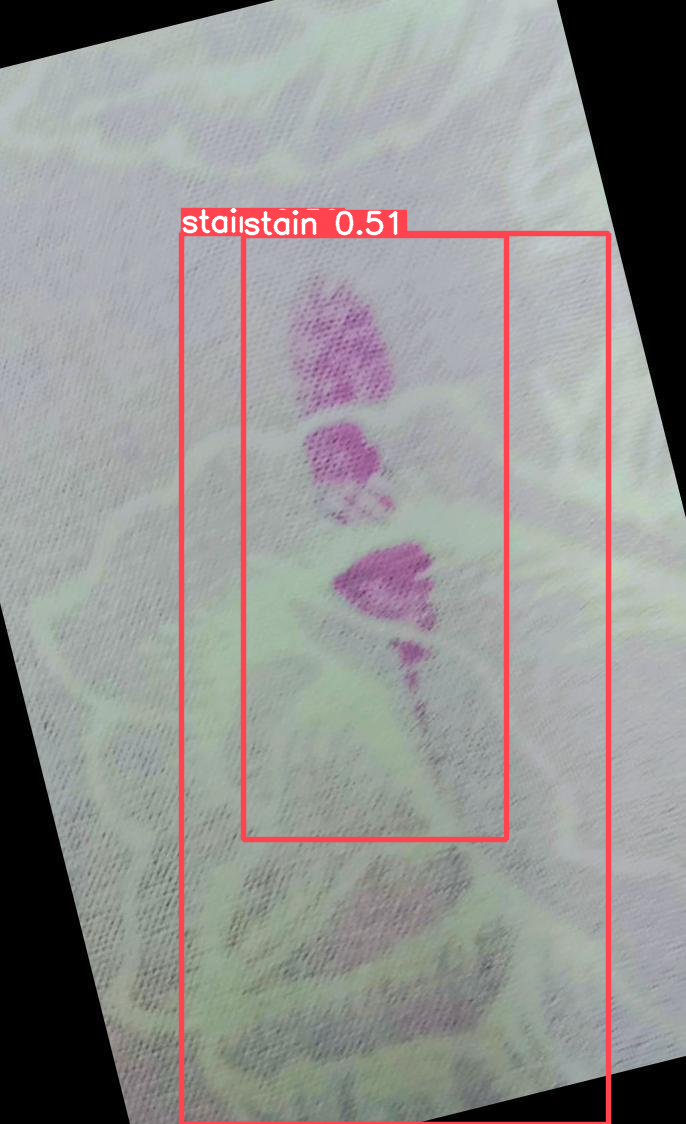


Prediction completed.
Confidence threshold: 0.35


In [ ]:


from ultralytics import YOLO
from pathlib import Path
from IPython.display import display
from PIL import Image


BEST = Path(
    "/kaggle/working/E_EAF_YOLO11n/runs/"
    "E_EAF_YOLO11n/weights/best.pt"
)

model = YOLO(str(BEST))

test_image_dir = (
    DATASET_DIR
    / test_name
    / "images"
)

test_images = [
    p for p in test_image_dir.iterdir()
    if p.suffix.lower() in IMAGE_EXTS
]

if not test_images:
    raise FileNotFoundError("No test images found.")

# Change this number to display another image
IMAGE_INDEX = 4

sample_image = test_images[IMAGE_INDEX]

print("Input image:")
print(sample_image)


results = model.predict(
    source=str(sample_image),
    imgsz=640,
    conf=BEST_CONF,
    device=0,
    save=True,
    project=str(RES_DIR / "prediction"),
    name="display",
    exist_ok=True,
    verbose=False
)


result_image = results[0].plot()

display(
    Image.fromarray(result_image[..., ::-1])
)

print("\nPrediction completed.")
print("Confidence threshold:", BEST_CONF)

Input image:
/kaggle/input/datasets/muhammadharisabid/fabricdefectntu/test/images/IMG-20231009-WA0054_jpg.rf.2a046342fd2e6a08891fa249508f82ca.jpg
Results saved to /kaggle/working/E_EAF_YOLO11n/results/prediction/display


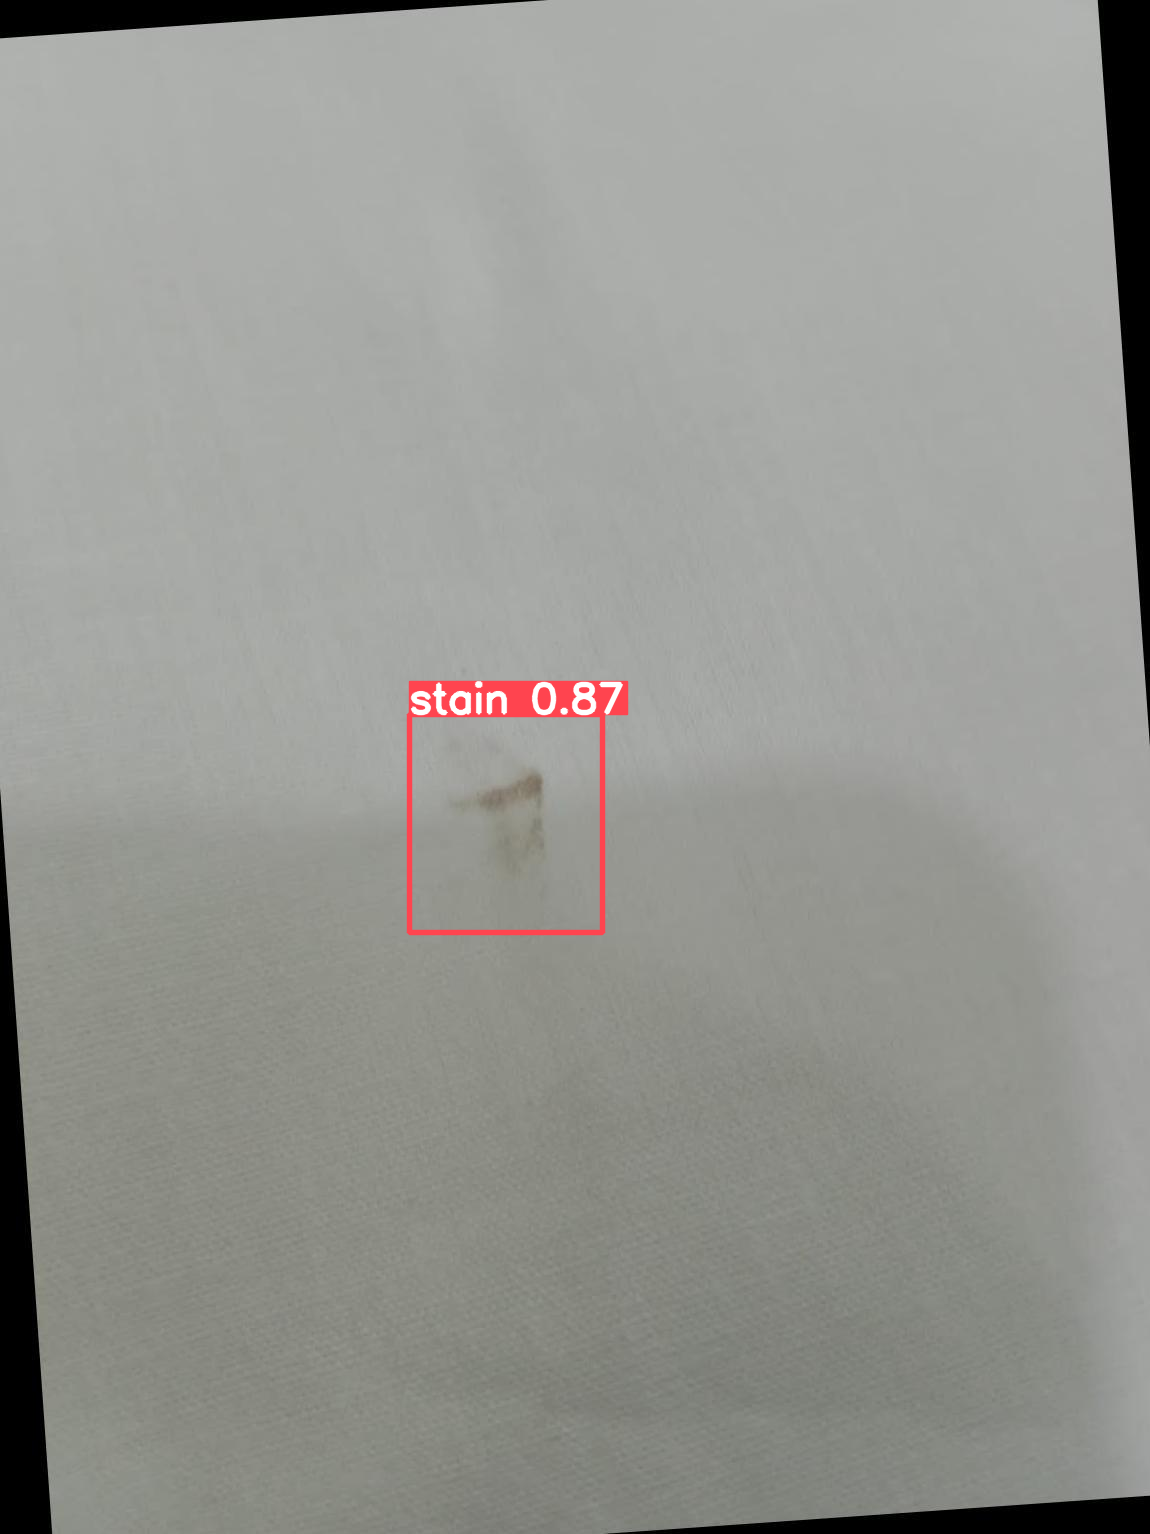


Prediction completed.
Confidence threshold: 0.35


In [ ]:


from ultralytics import YOLO
from pathlib import Path
from IPython.display import display
from PIL import Image

BEST = Path(
    "/kaggle/working/E_EAF_YOLO11n/runs/"
    "E_EAF_YOLO11n/weights/best.pt"
)

model = YOLO(str(BEST))


test_image_dir = (
    DATASET_DIR
    / test_name
    / "images"
)

test_images = [
    p for p in test_image_dir.iterdir()
    if p.suffix.lower() in IMAGE_EXTS
]

if not test_images:
    raise FileNotFoundError("No test images found.")

IMAGE_INDEX = 80

sample_image = test_images[IMAGE_INDEX]

print("Input image:")
print(sample_image)


results = model.predict(
    source=str(sample_image),
    imgsz=640,
    conf=BEST_CONF,
    device=0,
    save=True,
    project=str(RES_DIR / "prediction"),
    name="display",
    exist_ok=True,
    verbose=False
)


result_image = results[0].plot()

display(
    Image.fromarray(result_image[..., ::-1])
)

print("\nPrediction completed.")
print("Confidence threshold:", BEST_CONF)

In [ ]:


print("================================================")
print("           MODEL PERFORMANCE — TEST SET")
print("================================================")

accuracy_table = pd.DataFrame([{
    "Model": TAG,
    "Precision": test_row["Precision"],
    "Recall": test_row["Recall"],
    "mAP@50": test_row["mAP50"],
    "mAP@75": test_row["mAP75"],
    "mAP@50:95": test_row["mAP50-95"],
}])

percentage_table = accuracy_table.copy()

for column in [
    "Precision",
    "Recall",
    "mAP@50",
    "mAP@75",
    "mAP@50:95"
]:
    percentage_table[column] = (
        percentage_table[column] * 100
    ).round(2)

display(percentage_table)

print("================================================")
print("Interpretation:")
print("Precision   :", f"{test_row['Precision']*100:.2f}%")
print("Recall      :", f"{test_row['Recall']*100:.2f}%")
print("mAP@50      :", f"{test_row['mAP50']*100:.2f}%")
print("mAP@75      :", f"{test_row['mAP75']*100:.2f}%")
print("mAP@50:95   :", f"{test_row['mAP50-95']*100:.2f}%")
print("================================================")

           MODEL PERFORMANCE — TEST SET


,Model,Precision,Recall,mAP@50,mAP@75,mAP@50:95
0,E_EAF_YOLO11n,84.03,83.89,82.83,54.9,52.6


Interpretation:
Precision   : 84.03%
Recall      : 83.89%
mAP@50      : 82.83%
mAP@75      : 54.90%
mAP@50:95   : 52.60%


In [ ]:


PACKAGE_DIR = (
    Path("/kaggle/working")
    / f"{TAG}_FINAL"
)


if PACKAGE_DIR.exists():

    shutil.rmtree(
        PACKAGE_DIR
    )


PACKAGE_DIR.mkdir(
    parents=True
)

shutil.copytree(

    FINAL_DIR,

    PACKAGE_DIR / "model",

    dirs_exist_ok=True

)

if RES_DIR.exists():

    shutil.copytree(

        RES_DIR,

        PACKAGE_DIR / "results",

        dirs_exist_ok=True

    )


shutil.copy2(

    DATA_YAML,

    PACKAGE_DIR / "data.yaml"

)



archive = shutil.make_archive(

    str(
        Path("/kaggle/working")
        / TAG
    ),

    "zip",

    root_dir=PACKAGE_DIR.parent,

    base_dir=PACKAGE_DIR.name

)


print("============================================")
print("              TRAINING COMPLETE")
print("============================================")

print(
    "Best model:",
    FINAL_BEST
)

print(
    "ZIP:",
    archive
)

print(
    "Results:",
    RES_DIR
)

print(
    "Best F1 confidence:",
    BEST_CONF
)

print("============================================")

              TRAINING COMPLETE
Best model: /kaggle/working/E_EAF_YOLO11n/final_model/best.pt
ZIP: /kaggle/working/E_EAF_YOLO11n.zip
Results: /kaggle/working/E_EAF_YOLO11n/results
Best F1 confidence: 0.35
